In [13]:
# # This Python 3 environment comes with many helpful analytics libraries installed
# # It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# # For example, here's several helpful packages to load

# import numpy as np # linear algebra
# import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# # Input data files are available in the read-only "../input/" directory
# # For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

# import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

# # You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# # You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [14]:
# Run this in a Colab cell
!pip install torch-scatter torch-sparse torch-geometric -f https://data.pyg.org/whl/torch-2.0.0+cu118.html


Looking in links: https://data.pyg.org/whl/torch-2.0.0+cu118.html


In [15]:
# import os
# import glob
# import torch
# import torch.nn as nn
# import torch.nn.functional as F
# from torchvision import transforms
# from torchvision.models import convnext_tiny, ConvNeXt_Tiny_Weights
# from torch.utils.data import DataLoader, Dataset, Subset
# from sklearn.model_selection import train_test_split
# from PIL import Image
# from torch_geometric.data import Data
# from torch_geometric.nn import GCNConv
# import matplotlib.pyplot as plt
# from tqdm import tqdm

# # Check for GPU
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# # 1. Image Preprocessing
# transform = transforms.Compose([
#     transforms.Resize((224, 224)),
#     transforms.ToTensor()
# ])

# # 2. Custom Dataset
# class MushroomDataset(Dataset):
#     def __init__(self, root_dir, transform=None):
#         self.images = []
#         self.labels = []
#         self.transform = transform
#         self.classes = sorted(os.listdir(root_dir))
#         for idx, label in enumerate(self.classes):
#             for img_path in glob.glob(os.path.join(root_dir, label, "*.jpg")):
#                 self.images.append(img_path)
#                 self.labels.append(idx)

#     def __len__(self):
#         return len(self.images)

#     def __getitem__(self, idx):
#         img = Image.open(self.images[idx]).convert("RGB")
#         label = self.labels[idx]
#         if self.transform:
#             img = self.transform(img)
#         return img, label

# dataset = MushroomDataset(root_dir="/kaggle/input/split-dataset-of-fish/split dataset of fish/train", transform=transform)

# # 3. Train/Validation Split
# indices = list(range(len(dataset)))
# train_idx, val_idx = train_test_split(indices, test_size=0.2, stratify=dataset.labels, random_state=42)
# train_dataset = Subset(dataset, train_idx)
# val_dataset = Subset(dataset, val_idx)

# train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
# val_loader = DataLoader(val_dataset, batch_size=128, shuffle=False)

# # 4. ConvNeXt Feature Extractor
# class ConvNeXtFeatureExtractor(nn.Module):
#     def __init__(self):
#         super().__init__()
#         model = convnext_tiny(weights=ConvNeXt_Tiny_Weights.DEFAULT)
#         self.backbone = nn.Sequential(*list(model.features.children()))

#     def forward(self, x):
#         return self.backbone(x)  # (B, C, H, W)

# convnext_model = ConvNeXtFeatureExtractor().to(device).eval()

# # 5. Convert CNN feature map to graph
# def image_to_graph(features, label):
#     B, C, H, W = features.shape
#     graphs = []

#     for b in range(B):
#         feature_map = features[b]  # (C, H, W)
#         x = feature_map.permute(1, 2, 0).reshape(-1, C)  # (H*W, C)

#         # Grid edges
#         edges = []
#         for i in range(H):
#             for j in range(W):
#                 idx = i * W + j
#                 if i + 1 < H:
#                     edges.append((idx, idx + W))
#                     edges.append((idx + W, idx))
#                 if j + 1 < W:
#                     edges.append((idx, idx + 1))
#                     edges.append((idx + 1, idx))

#         edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
#         y = torch.tensor([label[b]], dtype=torch.long)

#         graphs.append(Data(x=x, edge_index=edge_index, y=y))

#     return graphs

# # 6. GCN Classifier
# class GCNClassifier(nn.Module):
#     def __init__(self, input_dim=768, hidden_dim=64, output_dim=10):
#         super().__init__()
#         self.conv1 = GCNConv(input_dim, hidden_dim)
#         self.conv2 = GCNConv(hidden_dim, hidden_dim)
#         self.fc = nn.Linear(hidden_dim, output_dim)

#     def forward(self, data):
#         x, edge_index = data.x, data.edge_index
#         x = F.relu(self.conv1(x, edge_index))
#         x = F.dropout(x, p=0.3, training=self.training)
#         x = F.relu(self.conv2(x, edge_index))
#         x = torch.mean(x, dim=0)  # Global mean pooling
#         return self.fc(x)

# gcn_model = GCNClassifier(input_dim=768, output_dim=len(dataset.classes)).to(device)
# optimizer = torch.optim.Adam(gcn_model.parameters(), lr=0.001)
# criterion = nn.CrossEntropyLoss()

# # 7. Metrics Storage
# train_losses, val_losses = [], []
# train_accuracies, val_accuracies = [], []

# # 8. Training Loop
# for epoch in range(10):
#     gcn_model.train()
#     total_loss = 0
#     correct = 0
#     total = 0

#     for img_batch, label_batch in tqdm(train_loader, desc=f"Epoch {epoch+1} - Train"):
#         img_batch = img_batch.to(device)
#         label_batch = label_batch.to(device)

#         with torch.no_grad():
#             features = convnext_model(img_batch)

#         graphs = image_to_graph(features.cpu(), label_batch.cpu())

#         for graph in graphs:
#             graph = graph.to(device)
#             optimizer.zero_grad()
#             out = gcn_model(graph)
#             loss = criterion(out.unsqueeze(0), graph.y)
#             loss.backward()
#             optimizer.step()
#             total_loss += loss.item()
#             pred = out.argmax().item()
#             correct += int(pred == graph.y.item())
#             total += 1

#     train_acc = correct / total
#     train_losses.append(total_loss)
#     train_accuracies.append(train_acc)

#     # Validation
#     gcn_model.eval()
#     val_loss = 0
#     correct = 0
#     total = 0

#     for img_batch, label_batch in tqdm(val_loader, desc=f"Epoch {epoch+1} - Val"):
#         img_batch = img_batch.to(device)
#         label_batch = label_batch.to(device)

#         with torch.no_grad():
#             features = convnext_model(img_batch)
#             graphs = image_to_graph(features.cpu(), label_batch.cpu())

#             for graph in graphs:
#                 graph = graph.to(device)
#                 out = gcn_model(graph)
#                 loss = criterion(out.unsqueeze(0), graph.y)
#                 val_loss += loss.item()
#                 pred = out.argmax().item()
#                 correct += int(pred == graph.y.item())
#                 total += 1

#     val_acc = correct / total
#     val_losses.append(val_loss)
#     val_accuracies.append(val_acc)

#     print(f"Epoch {epoch+1} | Train Loss: {total_loss:.4f} | Train Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

# # 9. Plotting Loss & Accuracy
# epochs = range(1, len(train_losses) + 1)
# plt.figure(figsize=(12, 5))

# # Loss plot
# plt.subplot(1, 2, 1)
# plt.plot(epochs, train_losses, label="Train Loss")
# plt.plot(epochs, val_losses, label="Val Loss")
# plt.xlabel("Epoch")
# plt.ylabel("Loss")
# plt.title("Loss Over Epochs")
# plt.legend()

# # Accuracy plot
# plt.subplot(1, 2, 2)
# plt.plot(epochs, train_accuracies, label="Train Accuracy")
# plt.plot(epochs, val_accuracies, label="Val Accuracy")
# plt.xlabel("Epoch")
# plt.ylabel("Accuracy")
# plt.title("Accuracy Over Epochs")
# plt.legend()

# plt.tight_layout()
# plt.show()


***** gobal mean pooling *****

In [16]:
# import os
# import glob
# import torch
# import torch.nn as nn
# import torch.nn.functional as F
# from torchvision import transforms
# from torchvision.models import convnext_tiny, ConvNeXt_Tiny_Weights
# from torch.utils.data import DataLoader, Dataset, Subset
# from sklearn.model_selection import train_test_split
# from PIL import Image
# from torch_geometric.data import Data
# from torch_geometric.nn import GCNConv
# import matplotlib.pyplot as plt
# from tqdm import tqdm
# import seaborn as sns
# import numpy as np
# from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
# from sklearn.preprocessing import label_binarize

# # Check for GPU
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# # 1. Image Preprocessing
# transform = transforms.Compose([
#     transforms.Resize((224, 224)),
#     transforms.ToTensor()
# ])

# # 2. Custom Dataset
# class MushroomDataset(Dataset):
#     def __init__(self, root_dir, transform=None):
#         self.images = []
#         self.labels = []
#         self.transform = transform
#         self.classes = sorted(os.listdir(root_dir))
#         for idx, label in enumerate(self.classes):
#             for img_path in glob.glob(os.path.join(root_dir, label, "*.jpg")):
#                 self.images.append(img_path)
#                 self.labels.append(idx)

#     def __len__(self):
#         return len(self.images)

#     def __getitem__(self, idx):
#         img = Image.open(self.images[idx]).convert("RGB")
#         label = self.labels[idx]
#         if self.transform:
#             img = self.transform(img)
#         return img, label

# dataset = MushroomDataset(root_dir="/kaggle/input/split-dataset-of-fish/split dataset of fish/train", transform=transform)

# # 3. Train/Validation Split
# indices = list(range(len(dataset)))
# train_idx, val_idx = train_test_split(indices, test_size=0.2, stratify=dataset.labels, random_state=42)
# train_dataset = Subset(dataset, train_idx)
# val_dataset = Subset(dataset, val_idx)

# train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
# val_loader = DataLoader(val_dataset, batch_size=128, shuffle=False)

# # 4. ConvNeXt Feature Extractor
# class ConvNeXtFeatureExtractor(nn.Module):
#     def __init__(self):
#         super().__init__()
#         model = convnext_tiny(weights=ConvNeXt_Tiny_Weights.DEFAULT)
#         self.backbone = nn.Sequential(*list(model.features.children()))

#     def forward(self, x):
#         return self.backbone(x)  # (B, C, H, W)

# convnext_model = ConvNeXtFeatureExtractor().to(device).eval()

# # 5. Convert CNN feature map to graph
# def image_to_graph(features, label):
#     B, C, H, W = features.shape
#     graphs = []

#     for b in range(B):
#         feature_map = features[b]  # (C, H, W)
#         x = feature_map.permute(1, 2, 0).reshape(-1, C)  # (H*W, C)

#         # Grid edges
#         edges = []
#         for i in range(H):
#             for j in range(W):
#                 idx = i * W + j
#                 if i + 1 < H:
#                     edges.append((idx, idx + W))
#                     edges.append((idx + W, idx))
#                 if j + 1 < W:
#                     edges.append((idx, idx + 1))
#                     edges.append((idx + 1, idx))

#         edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
#         y = torch.tensor([label[b]], dtype=torch.long)

#         graphs.append(Data(x=x, edge_index=edge_index, y=y))

#     return graphs

# # 6. GCN Classifier
# class GCNClassifier(nn.Module):
#     def __init__(self, input_dim=768, hidden_dim=64, output_dim=10):
#         super().__init__()
#         self.conv1 = GCNConv(input_dim, hidden_dim)
#         self.conv2 = GCNConv(hidden_dim, hidden_dim)
#         self.fc = nn.Linear(hidden_dim, output_dim)

#     def forward(self, data):
#         x, edge_index = data.x, data.edge_index
#         x = F.relu(self.conv1(x, edge_index))
#         x = F.dropout(x, p=0.3, training=self.training)
#         x = F.relu(self.conv2(x, edge_index))
#         x = torch.mean(x, dim=0)  # Global mean pooling
#         return self.fc(x)

# gcn_model = GCNClassifier(input_dim=768, output_dim=len(dataset.classes)).to(device)
# optimizer = torch.optim.Adam(gcn_model.parameters(), lr=0.001)
# criterion = nn.CrossEntropyLoss()

# # 7. Metrics Storage
# train_losses, val_losses = [], []
# train_accuracies, val_accuracies = [], []

# # 8. Training Loop
# for epoch in range(10):
#     gcn_model.train()
#     total_loss = 0
#     correct = 0
#     total = 0

#     for img_batch, label_batch in tqdm(train_loader, desc=f"Epoch {epoch+1} - Train"):
#         img_batch = img_batch.to(device)
#         label_batch = label_batch.to(device)

#         with torch.no_grad():
#             features = convnext_model(img_batch)

#         graphs = image_to_graph(features.cpu(), label_batch.cpu())

#         for graph in graphs:
#             graph = graph.to(device)
#             optimizer.zero_grad()
#             out = gcn_model(graph)
#             loss = criterion(out.unsqueeze(0), graph.y)
#             loss.backward()
#             optimizer.step()
#             total_loss += loss.item()
#             pred = out.argmax().item()
#             correct += int(pred == graph.y.item())
#             total += 1

#     train_acc = correct / total
#     train_losses.append(total_loss)
#     train_accuracies.append(train_acc)

#     # Validation
#     gcn_model.eval()
#     val_loss = 0
#     correct = 0
#     total = 0

#     for img_batch, label_batch in tqdm(val_loader, desc=f"Epoch {epoch+1} - Val"):
#         img_batch = img_batch.to(device)
#         label_batch = label_batch.to(device)

#         with torch.no_grad():
#             features = convnext_model(img_batch)
#             graphs = image_to_graph(features.cpu(), label_batch.cpu())

#             for graph in graphs:
#                 graph = graph.to(device)
#                 out = gcn_model(graph)
#                 loss = criterion(out.unsqueeze(0), graph.y)
#                 val_loss += loss.item()
#                 pred = out.argmax().item()
#                 correct += int(pred == graph.y.item())
#                 total += 1

#     val_acc = correct / total
#     val_losses.append(val_loss)
#     val_accuracies.append(val_acc)

#     print(f"Epoch {epoch+1} | Train Loss: {total_loss:.4f} | Train Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

# # 9. Final Evaluation with Metrics
# all_preds = []
# all_labels = []

# for img_batch, label_batch in tqdm(val_loader, desc="Final Metrics"):
#     img_batch = img_batch.to(device)
#     label_batch = label_batch.to(device)

#     with torch.no_grad():
#         features = convnext_model(img_batch)
#         graphs = image_to_graph(features.cpu(), label_batch.cpu())

#         for i, graph in enumerate(graphs):
#             graph = graph.to(device)
#             out = gcn_model(graph)
#             pred = out.argmax().item()
#             true = graph.y.item()
#             all_preds.append(pred)
#             all_labels.append(true)

# # Confusion Matrix
# y_true = np.array(all_labels)
# y_pred = np.array(all_preds)

# plt.figure(figsize=(8, 6))
# cm = confusion_matrix(y_true, y_pred)
# sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=dataset.classes, yticklabels=dataset.classes)
# plt.xlabel("Predicted")
# plt.ylabel("True")
# plt.title("Confusion Matrix")
# plt.show()

# # Classification Report
# print("Classification Report:")
# print(classification_report(y_true, y_pred, target_names=dataset.classes))

# # ROC Curve
# n_classes = len(dataset.classes)
# y_true_bin = label_binarize(y_true, classes=list(range(n_classes)))
# y_pred_prob = np.zeros((len(y_pred), n_classes))

# counter = 0
# for img_batch, label_batch in tqdm(val_loader, desc="ROC Probabilities"):
#     img_batch = img_batch.to(device)
#     label_batch = label_batch.to(device)

#     with torch.no_grad():
#         features = convnext_model(img_batch)
#         graphs = image_to_graph(features.cpu(), label_batch.cpu())

#         for graph in graphs:
#             graph = graph.to(device)
#             out = gcn_model(graph)
#             probs = F.softmax(out, dim=0).cpu().numpy()
#             y_pred_prob[counter] = probs
#             counter += 1

# # Plot ROC Curve
# plt.figure(figsize=(10, 8))
# for i in range(n_classes):
#     fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_pred_prob[:, i])
#     roc_auc = auc(fpr, tpr)
#     plt.plot(fpr, tpr, label=f"{dataset.classes[i]} (AUC = {roc_auc:.2f})")

# plt.plot([0, 1], [0, 1], "k--")
# plt.xlim([0.0, 1.0])
# plt.ylim([0.0, 1.05])
# plt.xlabel("False Positive Rate")
# plt.ylabel("True Positive Rate")
# plt.title("Multi-Class ROC Curve")
# plt.legend(loc="lower right")
# plt.grid()
# plt.show()

# # 10. Plotting Loss & Accuracy
# epochs = range(1, len(train_losses) + 1)
# plt.figure(figsize=(12, 5))

# # Loss plot
# plt.subplot(1, 2, 1)
# plt.plot(epochs, train_losses, label="Train Loss")
# plt.plot(epochs, val_losses, label="Val Loss")
# plt.xlabel("Epoch")
# plt.ylabel("Loss")
# plt.title("Loss Over Epochs")
# plt.legend()

# # Accuracy plot
# plt.subplot(1, 2, 2)
# plt.plot(epochs, train_accuracies, label="Train Accuracy")
# plt.plot(epochs, val_accuracies, label="Val Accuracy")
# plt.xlabel("Epoch")
# plt.ylabel("Accuracy")
# plt.title("Accuracy Over Epochs")
# plt.legend()

# plt.tight_layout()
# plt.show()


In [17]:
# # Final Train and Validation Accuracy
# final_train_acc = train_accuracies[-1]
# final_val_acc = val_accuracies[-1]

# print(f"\n✅ Final Train Accuracy: {final_train_acc * 100:.2f}%")
# print(f"✅ Final Validation Accuracy: {final_val_acc * 100:.2f}%")


**GLOBAL MAX POOLING**

Using device: cuda
✅ Dataset length: 9000
✅ Classes: ['Black Sea Sprat', 'Gilt-Head Bream', 'Hourse Mackerel', 'Red Mullet', 'Red Sea Bream', 'Sea Bass', 'Shrimp', 'Striped Red Mullet', 'Trout']


Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth
100%|██████████| 109M/109M [00:00<00:00, 196MB/s] 


✅ Number of classes: 9


Epoch 1 - Val: 100%|██████████| 15/15 [00:37<00:00,  2.52s/it]


Epoch 1 | Train Loss: 815.4358 | Train Acc: 0.9654 | Val Loss: 18.8088 | Val Acc: 0.9961


...

Epoch 9 - Val: 100%|██████████| 15/15 [00:27<00:00,  1.86s/it]


Epoch 9 | Train Loss: 59.0818 | Train Acc: 0.9985 | Val Loss: 4.5087 | Val Acc: 0.9983


Epoch 10 - Val: 100%|██████████| 15/15 [00:27<00:00,  1.82s/it]


Epoch 10 | Train Loss: 23.8149 | Train Acc: 0.9994 | Val Loss: 8.1679 | Val Acc: 0.9983


Final Metrics: 100%|██████████| 15/15 [00:27<00:00,  1.81s/it]


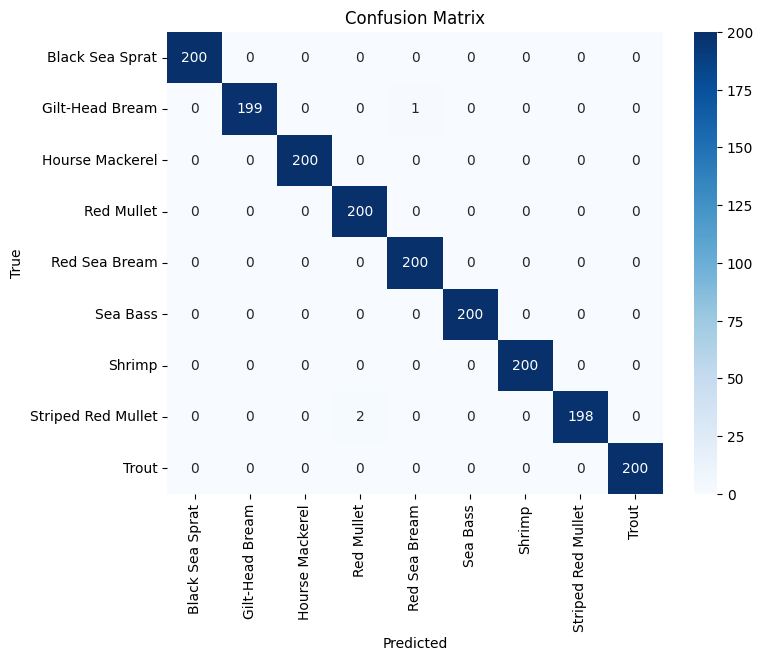

Classification Report:
                    precision    recall  f1-score   support

   Black Sea Sprat       1.00      1.00      1.00       200
   Gilt-Head Bream       1.00      0.99      1.00       200
   Hourse Mackerel       1.00      1.00      1.00       200
        Red Mullet       0.99      1.00      1.00       200
     Red Sea Bream       1.00      1.00      1.00       200
          Sea Bass       1.00      1.00      1.00       200
            Shrimp       1.00      1.00      1.00       200
Striped Red Mullet       1.00      0.99      0.99       200
             Trout       1.00      1.00      1.00       200

          accuracy                           1.00      1800
         macro avg       1.00      1.00      1.00      1800
      weighted avg       1.00      1.00      1.00      1800



ROC Probabilities: 100%|██████████| 15/15 [00:27<00:00,  1.82s/it]


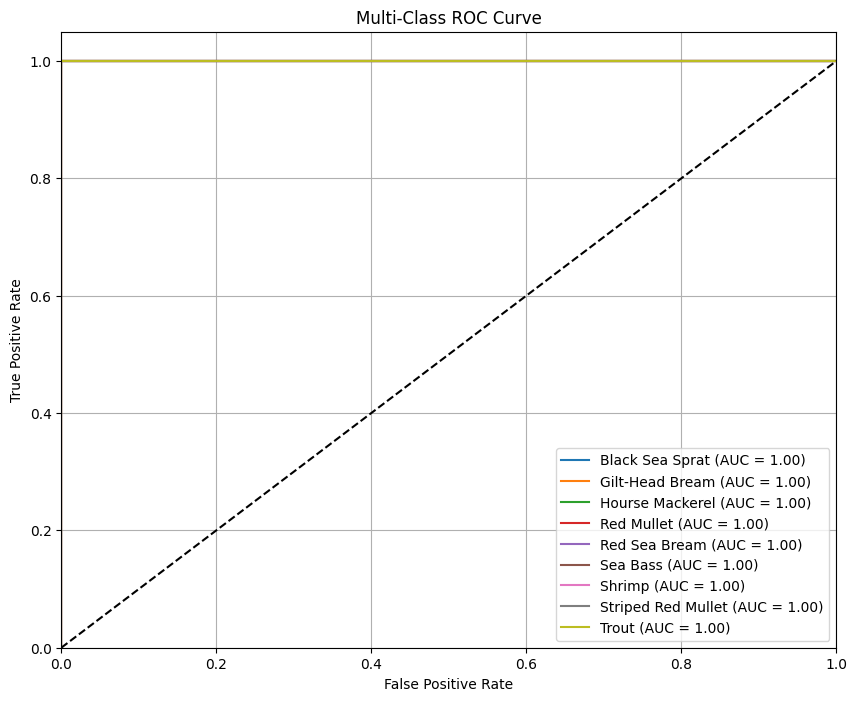

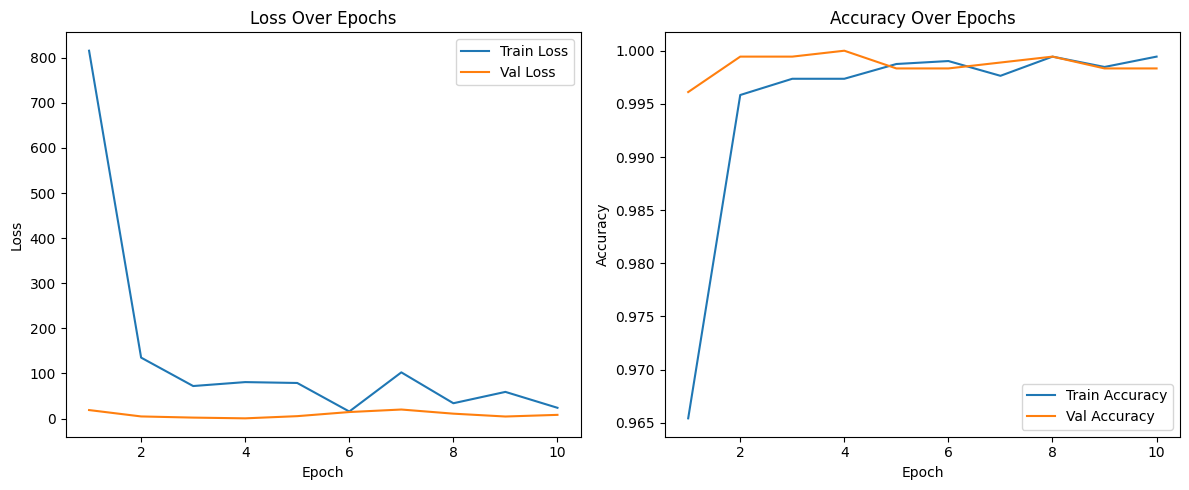

In [18]:
import os
import glob
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from torchvision.models import convnext_tiny, ConvNeXt_Tiny_Weights
from torch.utils.data import DataLoader, Dataset, Subset
from sklearn.model_selection import train_test_split
from PIL import Image
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv, global_max_pool
import matplotlib.pyplot as plt
from tqdm import tqdm
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
from sklearn.preprocessing import label_binarize

# =============================
# Check for GPU
# =============================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# =============================
# 1. Image Preprocessing
# =============================
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

# =============================
# 2. Custom Dataset
# =============================
class FishDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.images = []
        self.labels = []
        self.transform = transform
        self.classes = sorted([
            d for d in os.listdir(root_dir) 
            if os.path.isdir(os.path.join(root_dir, d))
        ])
        for idx, label in enumerate(self.classes):
            for ext in ("*.jpg", "*.jpeg", "*.png"):
                # 🔹 Recursive search inside nested folders
                for img_path in glob.glob(os.path.join(root_dir, label, "**", ext), recursive=True):
                    self.images.append(img_path)
                    self.labels.append(idx)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = Image.open(self.images[idx]).convert("RGB")
        label = self.labels[idx]
        if self.transform:
            img = self.transform(img)
        return img, label

# =============================
# Load dataset
# =============================
dataset = FishDataset(
    root_dir="/kaggle/input/fishcom-1-dataset/Fish_Dataset com-1",
    transform=transform
)

print("✅ Dataset length:", len(dataset))
print("✅ Classes:", dataset.classes)
if len(dataset) == 0:
    raise RuntimeError("❌ Dataset is empty. Check dataset path or file extensions!")

# =============================
# 3. Train/Validation Split
# =============================
indices = list(range(len(dataset)))
train_idx, val_idx = train_test_split(
    indices, test_size=0.2, stratify=dataset.labels, random_state=42
)
train_dataset = Subset(dataset, train_idx)
val_dataset = Subset(dataset, val_idx)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=128, shuffle=False)

# =============================
# 4. ConvNeXt Feature Extractor
# =============================
class ConvNeXtFeatureExtractor(nn.Module):
    def __init__(self):
        super().__init__()
        model = convnext_tiny(weights=ConvNeXt_Tiny_Weights.DEFAULT)
        self.backbone = nn.Sequential(*list(model.features.children()))

    def forward(self, x):
        return self.backbone(x)  # (B, C, H, W)

convnext_model = ConvNeXtFeatureExtractor().to(device).eval()

# =============================
# 5. Convert CNN feature map to graph
# =============================
def image_to_graph(features, label):
    B, C, H, W = features.shape
    graphs = []

    for b in range(B):
        feature_map = features[b]  # (C, H, W)
        x = feature_map.permute(1, 2, 0).reshape(-1, C)  # (H*W, C)

        # Build grid edges
        edges = []
        for i in range(H):
            for j in range(W):
                idx = i * W + j
                if i + 1 < H:
                    edges.append((idx, idx + W))
                    edges.append((idx + W, idx))
                if j + 1 < W:
                    edges.append((idx, idx + 1))
                    edges.append((idx + 1, idx))

        edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
        y = torch.tensor([label[b]], dtype=torch.long)

        graphs.append(Data(x=x, edge_index=edge_index, y=y))

    return graphs

# =============================
# 6. GCN Classifier (Global Max Pooling)
# =============================
class GCNClassifier(nn.Module):
    def __init__(self, input_dim=768, hidden_dim=64, output_dim=10):
        super().__init__()
        self.conv1 = GCNConv(input_dim, hidden_dim)
        self.conv2 = GCNConv(hidden_dim, hidden_dim)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, data):
        x, edge_index = data.x, data.edge_index
        x = F.relu(self.conv1(x, edge_index))
        x = F.dropout(x, p=0.3, training=self.training)
        x = F.relu(self.conv2(x, edge_index))
        batch = getattr(data, "batch", torch.zeros(x.size(0), dtype=torch.long, device=x.device))
        x = global_max_pool(x, batch)
        return self.fc(x)

num_classes = len(dataset.classes)
print("✅ Number of classes:", num_classes)

gcn_model = GCNClassifier(input_dim=768, output_dim=num_classes).to(device)
optimizer = torch.optim.Adam(gcn_model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

# =============================
# 7. Metrics Storage
# =============================
train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []

# =============================
# 8. Training Loop
# =============================
for epoch in range(10):
    gcn_model.train()
    total_loss = 0
    correct = 0
    total = 0

    for img_batch, label_batch in tqdm(train_loader, desc=f"Epoch {epoch+1} - Train"):
        img_batch = img_batch.to(device)
        label_batch = label_batch.to(device)

        with torch.no_grad():
            features = convnext_model(img_batch)

        graphs = image_to_graph(features.cpu(), label_batch.cpu())

        for graph in graphs:
            graph = graph.to(device)
            optimizer.zero_grad()
            out = gcn_model(graph)
            loss = criterion(out, graph.y)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
            pred = out.argmax().item()
            correct += int(pred == graph.y.item())
            total += 1

    train_acc = correct / total
    train_losses.append(total_loss)
    train_accuracies.append(train_acc)

    # Validation
    gcn_model.eval()
    val_loss = 0
    correct = 0
    total = 0

    for img_batch, label_batch in tqdm(val_loader, desc=f"Epoch {epoch+1} - Val"):
        img_batch = img_batch.to(device)
        label_batch = label_batch.to(device)

        with torch.no_grad():
            features = convnext_model(img_batch)
            graphs = image_to_graph(features.cpu(), label_batch.cpu())

            for graph in graphs:
                graph = graph.to(device)
                out = gcn_model(graph)
                loss = criterion(out, graph.y)
                val_loss += loss.item()
                pred = out.argmax().item()
                correct += int(pred == graph.y.item())
                total += 1

    val_acc = correct / total
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    print(f"Epoch {epoch+1} | Train Loss: {total_loss:.4f} | Train Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

# =============================
# 9. Final Evaluation with Metrics
# =============================
all_preds = []
all_labels = []

for img_batch, label_batch in tqdm(val_loader, desc="Final Metrics"):
    img_batch = img_batch.to(device)
    label_batch = label_batch.to(device)

    with torch.no_grad():
        features = convnext_model(img_batch)
        graphs = image_to_graph(features.cpu(), label_batch.cpu())

        for i, graph in enumerate(graphs):
            graph = graph.to(device)
            out = gcn_model(graph)
            pred = out.argmax().item()
            true = graph.y.item()
            all_preds.append(pred)
            all_labels.append(true)

# Confusion Matrix
y_true = np.array(all_labels)
y_pred = np.array(all_preds)

plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=dataset.classes,
            yticklabels=dataset.classes)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

# Classification Report
print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=dataset.classes))

# ROC Curve
n_classes = len(dataset.classes)
y_true_bin = label_binarize(y_true, classes=list(range(n_classes)))
y_pred_prob = np.zeros((len(y_pred), n_classes))

counter = 0
for img_batch, label_batch in tqdm(val_loader, desc="ROC Probabilities"):
    img_batch = img_batch.to(device)
    label_batch = label_batch.to(device)

    with torch.no_grad():
        features = convnext_model(img_batch)
        graphs = image_to_graph(features.cpu(), label_batch.cpu())

        for graph in graphs:
            graph = graph.to(device)
            out = gcn_model(graph)
            probs = F.softmax(out, dim=1).cpu().numpy()
            y_pred_prob[counter] = probs[0]
            counter += 1

# Plot ROC Curve
plt.figure(figsize=(10, 8))
for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_pred_prob[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{dataset.classes[i]} (AUC = {roc_auc:.2f})")

plt.plot([0, 1], [0, 1], "k--")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multi-Class ROC Curve")
plt.legend(loc="lower right")
plt.grid()
plt.show()

# =============================
# 10. Plotting Loss & Accuracy
# =============================
epochs = range(1, len(train_losses) + 1)
plt.figure(figsize=(12, 5))

# Loss plot
plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, label="Train Loss")
plt.plot(epochs, val_losses, label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss Over Epochs")
plt.legend()

# Accuracy plot
plt.subplot(1, 2, 2)
plt.plot(epochs, train_accuracies, label="Train Accuracy")
plt.plot(epochs, val_accuracies, label="Val Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy Over Epochs")
plt.legend()

plt.tight_layout()
plt.show()


In [19]:
# # Final Train and Validation Accuracy
final_train_acc = train_accuracies[-1]
final_val_acc = val_accuracies[-1]

print(f"\n✅ Final Train Accuracy: {final_train_acc * 100:.2f}%")
print(f"✅ Final Validation Accuracy: {final_val_acc * 100:.2f}%")


✅ Final Train Accuracy: 99.94%
✅ Final Validation Accuracy: 99.83%
